
========== REGRESSION RESULTS ==========
Model  Slope (m)  Intercept (c)  Train MSE  Validation MSE  Test MSE
  OLS     2.0000         3.0000     0.0000          0.0000    0.0000
Lasso     1.9000         3.3000     0.0200          0.1250    0.3050
Ridge     1.8182         3.5455     0.0661          0.4132    1.0083


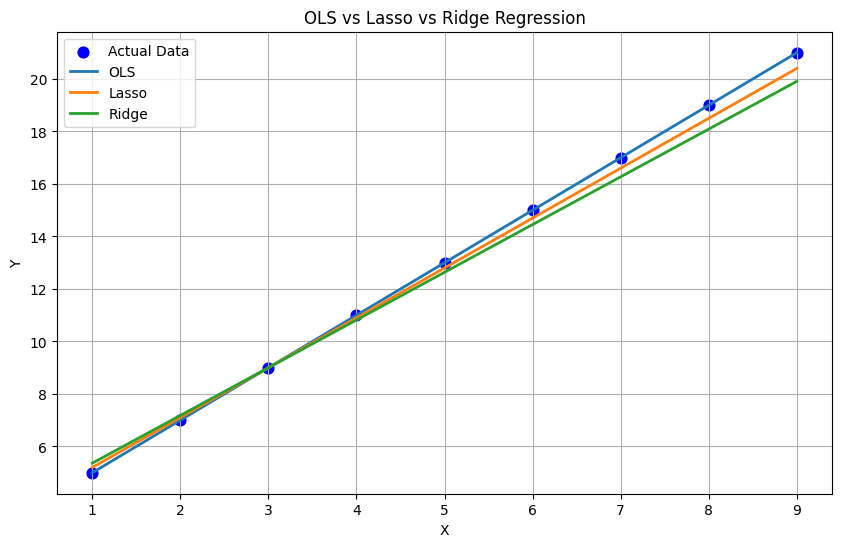


========== OLS ==========
Slope (m): 2.0
Intercept (c): 3.0
Train MSE: 0.0
Validation MSE: 0.0
Test MSE: 0.0

========== Lasso ==========
Slope (m): 1.9
Intercept (c): 3.3
Train MSE: 0.02
Validation MSE: 0.125
Test MSE: 0.305

========== Ridge ==========
Slope (m): 1.8182
Intercept (c): 3.5455
Train MSE: 0.0661
Validation MSE: 0.4132
Test MSE: 1.0083


In [4]:
# ==========================================
# OLS, LASSO AND RIDGE REGRESSION
# Train MSE, Validation MSE and Test MSE
# ==========================================

# 1. Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_squared_error


# 2. Create Dataset
X = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9]).reshape(-1, 1)
y = np.array([5, 7, 9, 11, 13, 15, 17, 19, 21])


# 3. Split Dataset (60:20:20)
X_train, y_train = X[:5], y[:5]
X_valid, y_valid = X[5:7], y[5:7]
X_test, y_test = X[7:], y[7:]


# 4. Create Models
models = {
    "OLS": LinearRegression(),
    "Lasso": Lasso(alpha=0.2),
    "Ridge": Ridge(alpha=1.0)
}


# 5. Train Models and Calculate MSE
results = []

for name, model in models.items():

    # Train model
    model.fit(X_train, y_train)

    # Predictions
    train_pred = model.predict(X_train)
    valid_pred = model.predict(X_valid)
    test_pred = model.predict(X_test)

    # Calculate MSE
    train_mse = mean_squared_error(y_train, train_pred)
    valid_mse = mean_squared_error(y_valid, valid_pred)
    test_mse = mean_squared_error(y_test, test_pred)

    # Store results
    results.append({
        "Model": name,
        "Slope (m)": model.coef_[0],
        "Intercept (c)": model.intercept_,
        "Train MSE": train_mse,
        "Validation MSE": valid_mse,
        "Test MSE": test_mse
    })


# 6. Display Results
result_df = pd.DataFrame(results)

print("\n========== REGRESSION RESULTS ==========")
print(result_df.round(4).to_string(index=False))


# 7. Plot Regression Lines
plt.figure(figsize=(10, 6))

plt.scatter(X, y, color='blue', s=60, label='Actual Data')

X_line = np.linspace(1, 9, 100).reshape(-1, 1)

for name, model in models.items():
    y_line = model.predict(X_line)
    plt.plot(X_line, y_line, label=name, linewidth=2)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("OLS vs Lasso vs Ridge Regression")
plt.legend()
plt.grid(True)
plt.show()


# 8. Display Individual Model Results
for row in results:

    print("\n==========", row["Model"], "==========")
    print("Slope (m):", round(row["Slope (m)"], 4))
    print("Intercept (c):", round(row["Intercept (c)"], 4))
    print("Train MSE:", round(row["Train MSE"], 4))
    print("Validation MSE:", round(row["Validation MSE"], 4))
    print("Test MSE:", round(row["Test MSE"], 4))